In [170]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/iris/Iris.csv
/kaggle/input/datasets/uciml/iris/database.sqlite


In [171]:
df=pd.read_csv('/kaggle/input/datasets/uciml/iris/Iris.csv')

In [172]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [173]:
df=df.iloc[:,1:]

In [174]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [175]:
from sklearn.preprocessing import LabelEncoder

In [176]:
encoder=LabelEncoder()


In [177]:
df['Species']=encoder.fit_transform(df['Species'])

In [178]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]

In [179]:
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [180]:
import seaborn as sns
import matplotlib.pyplot as plt

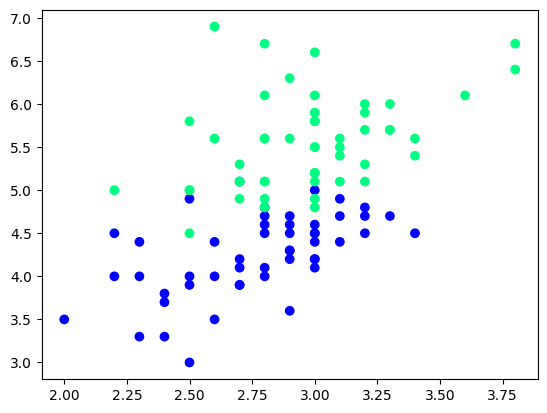

In [181]:
plt.scatter(df['SepalWidthCm'],df['PetalLengthCm'],c=df['Species'],cmap='winter')

In [182]:
df_train=df.iloc[:60,:].sample(10)
df_train

,SepalWidthCm,PetalLengthCm,Species
106,2.5,4.5,2
57,2.4,3.3,1
66,3.0,4.5,1
63,2.9,4.7,1
108,2.5,5.8,2
76,2.8,4.8,1
52,3.1,4.9,1
79,2.6,3.5,1
62,2.2,4.0,1
61,3.0,4.2,1


In [183]:
# Taking only 10 rows for training
df=df.sample(100)
df_train=df.iloc[:60,:].sample(10)
df_val=df.iloc[60:80,:].sample(5)
df_test=df.iloc[80:,:].sample(5)

In [184]:
df_train

,SepalWidthCm,PetalLengthCm,Species
137,3.1,5.5,2
95,3.0,4.2,1
69,2.5,3.9,1
54,2.8,4.6,1
144,3.3,5.7,2
72,2.5,4.9,1
90,2.6,4.4,1
60,2.0,3.5,1
63,2.9,4.7,1
115,3.2,5.3,2


In [185]:
df_val

,SepalWidthCm,PetalLengthCm,Species
123,2.7,4.9,2
58,2.9,4.6,1
71,2.8,4.0,1
66,3.0,4.5,1
96,2.9,4.2,1


In [186]:
df_test

,SepalWidthCm,PetalLengthCm,Species
64,2.9,3.6,1
138,3.0,4.8,2
88,3.0,4.1,1
55,2.8,4.5,1
132,2.8,5.6,2


In [187]:
X_test=df_val.iloc[:,0:2].values
y_test=df_val.iloc[:,-1].values

In [188]:
y_test

array([2, 1, 1, 1, 1])

<h1><b>case:1 Bagging

In [189]:
# Data for Tree 1
df_bag=df_train.sample(8,replace=True)
X=df_bag.iloc[:,0:2].values
y=df_bag.iloc[:,-1].values

In [190]:
df_bag

,SepalWidthCm,PetalLengthCm,Species
69,2.5,3.9,1
69,2.5,3.9,1
69,2.5,3.9,1
60,2.0,3.5,1
69,2.5,3.9,1
69,2.5,3.9,1
144,3.3,5.7,2
54,2.8,4.6,1


In [191]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score
from mlxtend.plotting import plot_decision_regions

In [192]:
df_bag1= DecisionTreeClassifier()

In [193]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    X_array=np.asarray(X)
    y_array=np.asarray(y).ravel()
    X=X_array
    y=y_array.astype(int)
    plot_decision_regions(X,y,clf=clf,legend=2)
    y_pred=clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

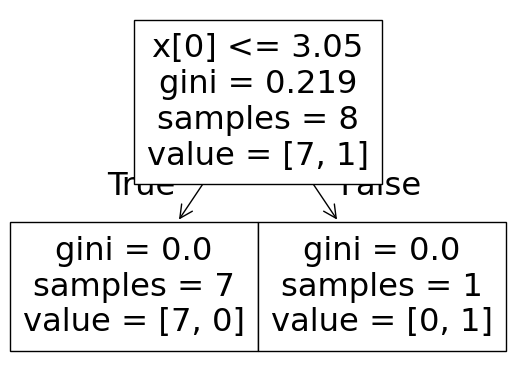

0.8


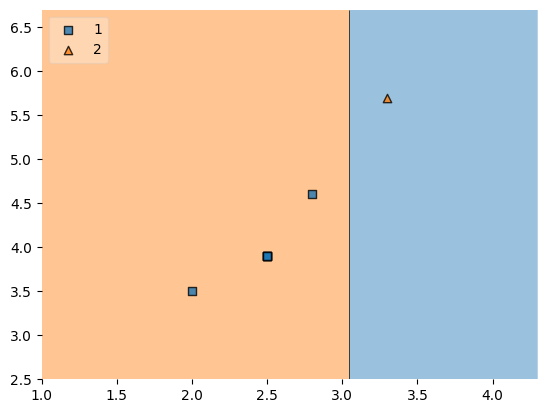

In [194]:
evaluate(df_bag1,X,y)

In [195]:
# Data for Tree 1
df_bag=df_train.sample(8,replace=True)
# Fetch X and y
X=df_train.iloc[:,0:2]
y=df_train.iloc[:,-1]

#print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
144,3.3,5.7,2
137,3.1,5.5,2
144,3.3,5.7,2
95,3.0,4.2,1
72,2.5,4.9,1
144,3.3,5.7,2
90,2.6,4.4,1
144,3.3,5.7,2


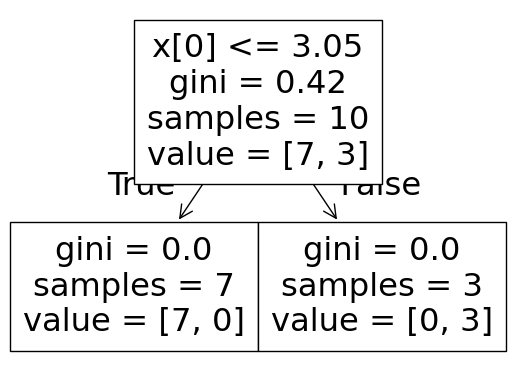

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


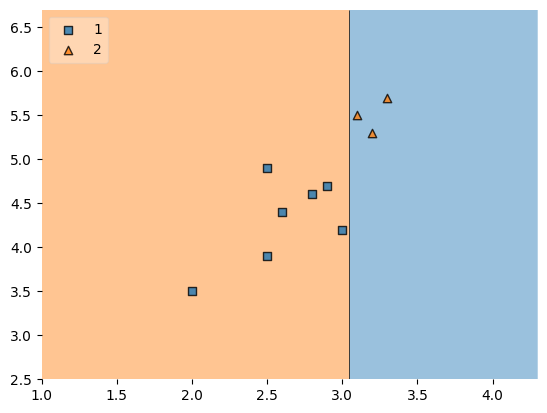

In [196]:
df_bag2=DecisionTreeClassifier()
evaluate(df_bag2,X,y)

In [197]:
# Data for Tree 1
df_bag=df_train.sample(8,replace=True)
# Fetch X and y
X=df_train.iloc[:,0:2]
y=df_train.iloc[:,-1]

#print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
54,2.8,4.6,1
115,3.2,5.3,2
69,2.5,3.9,1
63,2.9,4.7,1
69,2.5,3.9,1
144,3.3,5.7,2
72,2.5,4.9,1
144,3.3,5.7,2


In [198]:
df_bag3=DecisionTreeClassifier()

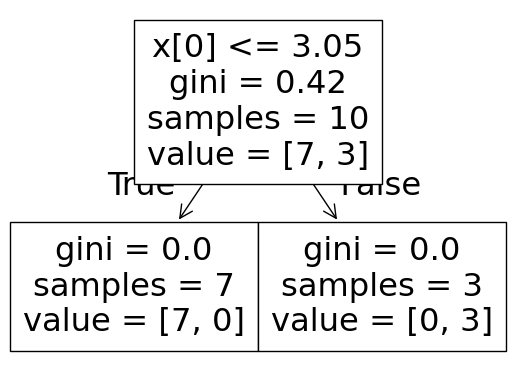

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


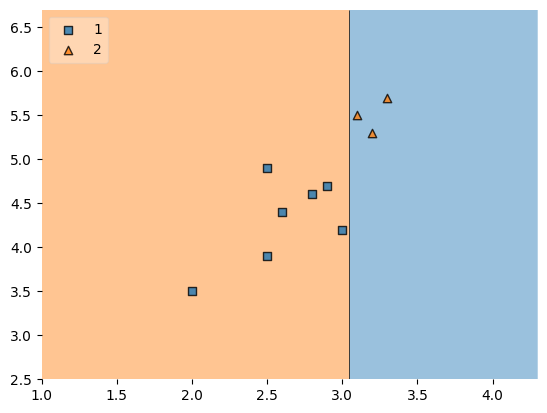

In [199]:
evaluate(df_bag3,X,y)

<h1><b> 2: predict 

In [200]:
df_test

,SepalWidthCm,PetalLengthCm,Species
64,2.9,3.6,1
138,3.0,4.8,2
88,3.0,4.1,1
55,2.8,4.5,1
132,2.8,5.6,2


In [201]:
print('1 prediction',df_bag1.predict(np.array([2.2,5.0]).reshape(1,2)))
print('2 prediction',df_bag2.predict(np.array([2.2,5.0]).reshape(1,2)))
print('3 prediction',df_bag3.predict(np.array([2.2,5.0]).reshape(1,2)))

1 prediction [1]
2 prediction [1]
3 prediction [1]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


<h1><b>Pasting

In [202]:
df_train

,SepalWidthCm,PetalLengthCm,Species
137,3.1,5.5,2
95,3.0,4.2,1
69,2.5,3.9,1
54,2.8,4.6,1
144,3.3,5.7,2
72,2.5,4.9,1
90,2.6,4.4,1
60,2.0,3.5,1
63,2.9,4.7,1
115,3.2,5.3,2


In [203]:
df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
72,2.5,4.9,1
63,2.9,4.7,1
54,2.8,4.6,1
90,2.6,4.4,1
137,3.1,5.5,2
69,2.5,3.9,1
144,3.3,5.7,2
115,3.2,5.3,2


<h1><b>Random Subspaces

In [207]:
df1=pd.read_csv('/kaggle/input/datasets/uciml/iris/Iris.csv')
df1=df1.sample(10)

In [208]:
df1.sample(10)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
29,30,4.7,3.2,1.6,0.2,Iris-setosa
103,104,6.3,2.9,5.6,1.8,Iris-virginica
25,26,5.0,3.0,1.6,0.2,Iris-setosa
81,82,5.5,2.4,3.7,1.0,Iris-versicolor
138,139,6.0,3.0,4.8,1.8,Iris-virginica
22,23,4.6,3.6,1.0,0.2,Iris-setosa
125,126,7.2,3.2,6.0,1.8,Iris-virginica
28,29,5.2,3.4,1.4,0.2,Iris-setosa
59,60,5.2,2.7,3.9,1.4,Iris-versicolor
2,3,4.7,3.2,1.3,0.2,Iris-setosa


In [209]:
df1.sample(2,replace=True,axis=1)

,Species,Species
25,Iris-setosa,Iris-setosa
28,Iris-setosa,Iris-setosa
138,Iris-virginica,Iris-virginica
22,Iris-setosa,Iris-setosa
81,Iris-versicolor,Iris-versicolor
29,Iris-setosa,Iris-setosa
59,Iris-versicolor,Iris-versicolor
2,Iris-setosa,Iris-setosa
125,Iris-virginica,Iris-virginica
103,Iris-virginica,Iris-virginica


<h1><b>Random Pateches

In [210]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
25,26,5.0,3.0,1.6,0.2,Iris-setosa
28,29,5.2,3.4,1.4,0.2,Iris-setosa
138,139,6.0,3.0,4.8,1.8,Iris-virginica
22,23,4.6,3.6,1.0,0.2,Iris-setosa
81,82,5.5,2.4,3.7,1.0,Iris-versicolor
29,30,4.7,3.2,1.6,0.2,Iris-setosa
59,60,5.2,2.7,3.9,1.4,Iris-versicolor
2,3,4.7,3.2,1.3,0.2,Iris-setosa
125,126,7.2,3.2,6.0,1.8,Iris-virginica
103,104,6.3,2.9,5.6,1.8,Iris-virginica


In [211]:
df1.sample(8,replace=True).sample(2,replace=True,axis=1)

,SepalWidthCm,PetalWidthCm
28,3.4,0.2
22,3.6,0.2
28,3.4,0.2
125,3.2,1.8
59,2.7,1.4
125,3.2,1.8
59,2.7,1.4
2,3.2,0.2
